# LeetCode #46: Permutations

https://leetcode.com/problems/permutations/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force** | $O(n \times n!)$ | $O(n)$ |
| **Optimal: Backtracking (Swap) ★** | $O(n \times n!)$ | $O(n)$ |

---

## Understanding the Methods

### Brute Force
Build each permutation by picking one unused element at a time from a copy of the array, tracking which indices have been consumed with a boolean array, and appending a copy of the path when length equals n. Produces correct results but allocates heavily per call.

### Optimal: Backtracking (Swap) ★
Partition the array into a "fixed" prefix (indices 0..start-1) and a "remaining" suffix (start..n-1). At each level swap position `start` with each position `i >= start` in turn, recurse with `start+1`, then swap back to restore the array. No extra memory is needed to track which elements are used.

**Why this is better than Brute Force:** In-place swapping eliminates the need for a separate "used" array and an extra path list; every operation modifies a single shared array, so the only extra memory is the call stack of depth $n$.

**Constraints:**
* 1 <= nums.length <= 6
* -10 <= nums[i] <= 10
* All integers in nums are unique

## Solutions

### C#

In [ ]:
public class Solution {
    public IList<IList<int>> Permute(int[] nums) {
        var result = new List<IList<int>>();
        Backtrack(nums, 0, result);
        return result;
    }

    private void Backtrack(int[] nums, int start, IList<IList<int>> result) {
        if (start == nums.Length) {
            // Every element is fixed — record a snapshot of the current permutation
            result.Add(new List<int>(nums));
            return;
        }
        for (int i = start; i < nums.Length; i++) {
            // Bring element i into the fixed prefix by swapping it to position start
            (nums[start], nums[i]) = (nums[i], nums[start]);
            Backtrack(nums, start + 1, result);
            // Restore the array so the next iteration sees the original suffix
            (nums[start], nums[i]) = (nums[i], nums[start]);
        }
    }
}

### Python

In [ ]:
class Solution:
    def permute(self, nums: list[int]) -> list[list[int]]:
        result = []

        def backtrack(start: int) -> None:
            if start == len(nums):
                # Every element is fixed — record a snapshot of the current permutation
                result.append(list(nums))
                return
            for i in range(start, len(nums)):
                # Bring element i into the fixed prefix by swapping it to position start
                nums[start], nums[i] = nums[i], nums[start]
                backtrack(start + 1)
                # Restore the array so the next iteration sees the original suffix
                nums[start], nums[i] = nums[i], nums[start]

        backtrack(0)
        return result

### Go

In [ ]:
func permute(nums []int) [][]int {
    result := [][]int{}
    var backtrack func(start int)
    backtrack = func(start int) {
        if start == len(nums) {
            // Every element is fixed — record a snapshot of the current permutation
            perm := make([]int, len(nums))
            copy(perm, nums)
            result = append(result, perm)
            return
        }
        for i := start; i < len(nums); i++ {
            // Bring element i into the fixed prefix by swapping it to position start
            nums[start], nums[i] = nums[i], nums[start]
            backtrack(start + 1)
            // Restore the array so the next iteration sees the original suffix
            nums[start], nums[i] = nums[i], nums[start]
        }
    }
    backtrack(0)
    return result
}

### Rust

In [ ]:
impl Solution {
    pub fn permute(mut nums: Vec<i32>) -> Vec<Vec<i32>> {
        let mut result = Vec::new();
        Self::backtrack(&mut nums, 0, &mut result);
        result
    }

    fn backtrack(nums: &mut Vec<i32>, start: usize, result: &mut Vec<Vec<i32>>) {
        if start == nums.len() {
            // Every element is fixed — record a snapshot of the current permutation
            result.push(nums.clone());
            return;
        }
        for i in start..nums.len() {
            // Bring element i into the fixed prefix by swapping it to position start
            nums.swap(start, i);
            Self::backtrack(nums, start + 1, result);
            // Restore the array so the next iteration sees the original suffix
            nums.swap(start, i);
        }
    }
}

## Example Scenarios

**1. Common Case**
**Input:** nums = [1, 2, 3]
The decision tree fixes one position per level: 3 choices, then 2, then 1. Every root-to-leaf path is a distinct permutation, giving $3! = 6$ results.

**2. Slightly Complex**
**Input:** nums = [1, 2, 3, 4]
The first position has 4 choices, and each hides an identical $3!$ subtree. Total leaves $= 4! = 24$; only the first-choice subtree is drawn in full.

**3. Edge Case: Time**
**Input:** nums = [1, 2, 3, 4, 5, 6]
The branching factor drops by one each level, so the leaf count is $6 \times 5 \times 4 \times 3 \times 2 \times 1 = 720$. Output size alone forces $O(n \cdot n!)$ time.

**4. Edge Case: Space**
**Input:** nums = [1, 2, 3, 4]
The swap-based backtracking mutates the input array in place and restores it, allocating no per-path list. Only the recursion stack grows, to depth $n$, so auxiliary space is $O(n)$.

**5. Almost-Impossible but Plausible**
**Input:** nums = [42]
With $n = 1$ the base case fires immediately and records the single element. The answer is $[[42]]$, not an empty list — $1! = 1$ permutation.


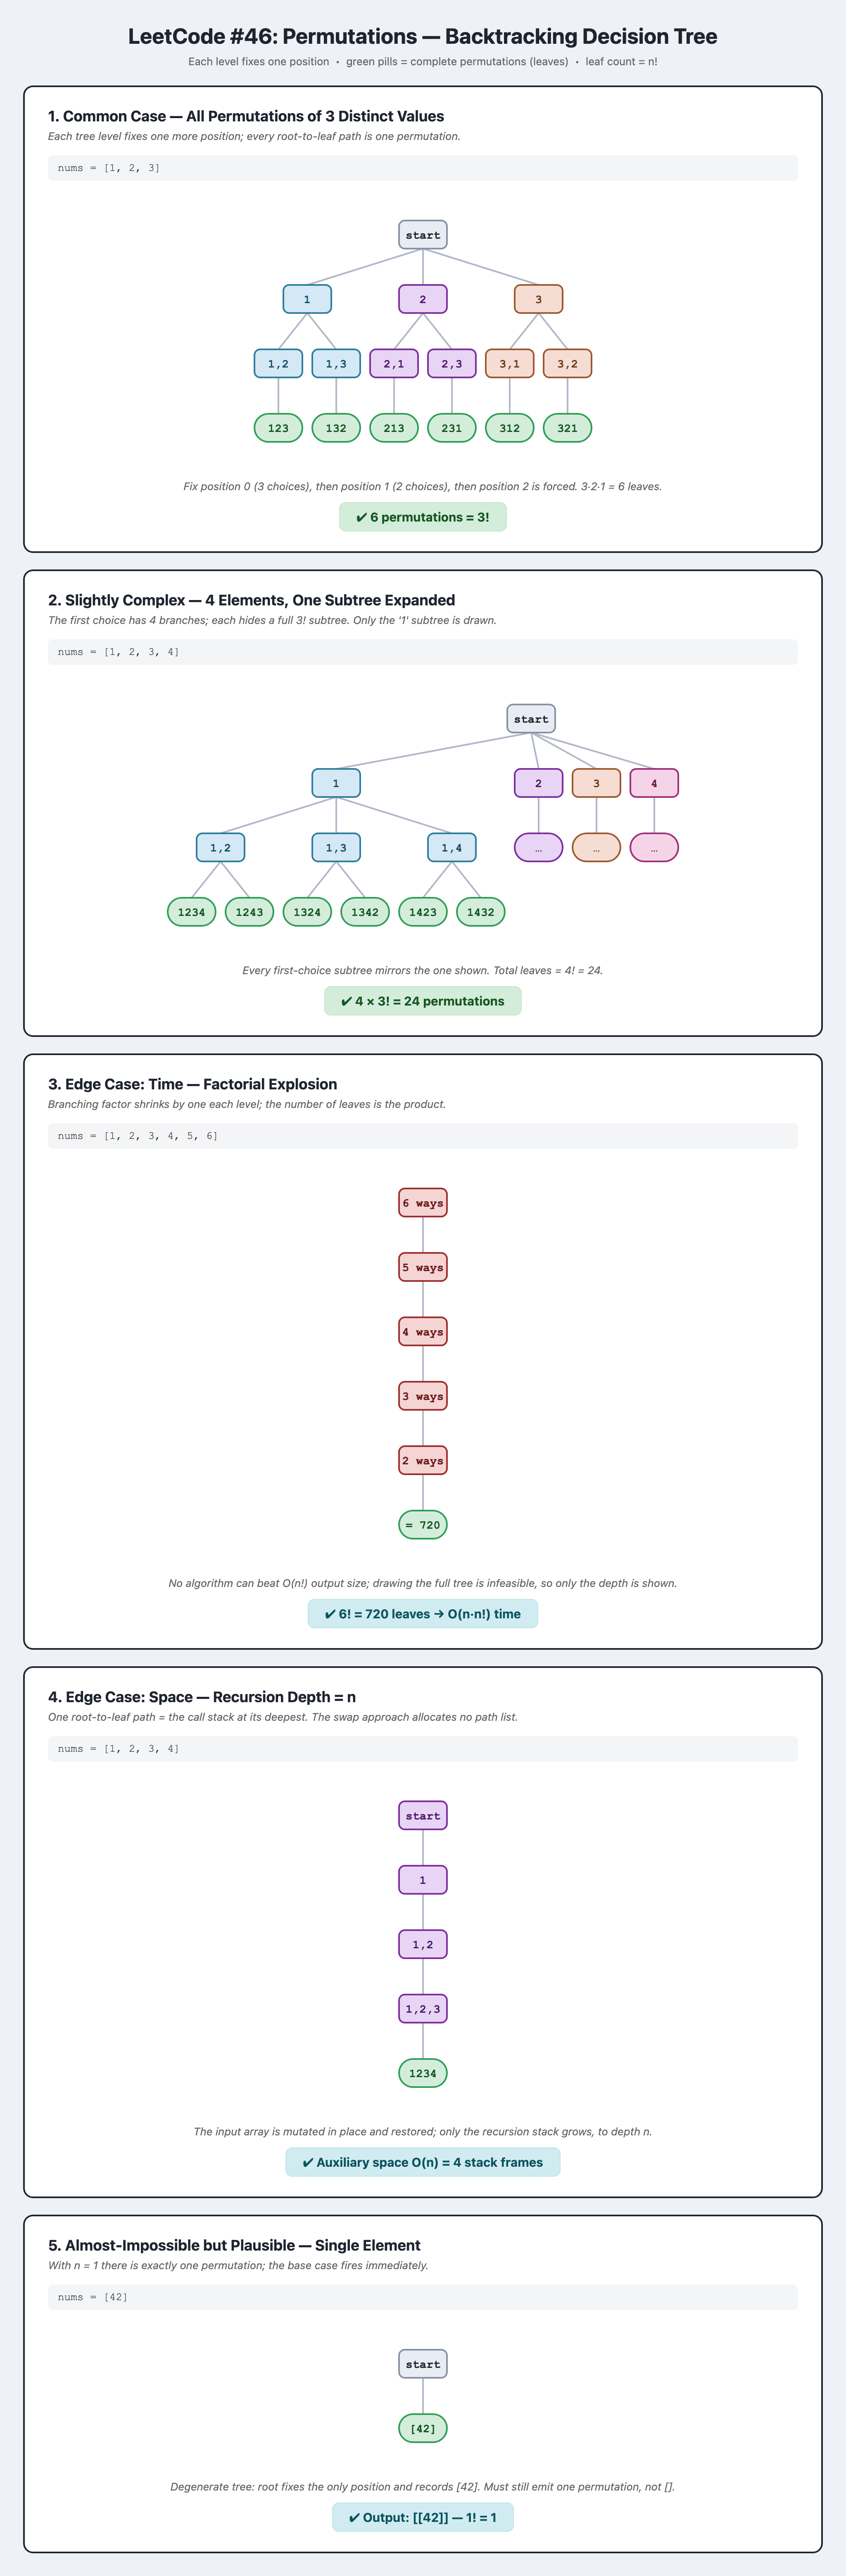